# Fraud Detection in Credit Card Transactions
**AI & ML Internship project - Elevate Labs**

**Goal:** detect fraudulent credit card transactions. Fraud is extremely rare here (492 of 284,807 = 0.17%), so plain accuracy is useless. A model that always says "legit" would be 99.8% accurate. I use precision, recall and PR-AUC instead.

**Dataset:** Kaggle *Credit Card Fraud Detection* (European cardholders, 2 days). Features `V1`-`V28` are anonymized PCA components, plus `Time` and `Amount`. Target `Class` = 1 for fraud.

**Plan:** split the data, scale, compare unsupervised anomaly detectors with supervised models (Logistic Regression, XGBoost with class weights, XGBoost with SMOTE), tune the threshold on a validation set, evaluate on a held-out test set.

## 1. Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

## 2. Load the data

In [2]:
df = pd.read_csv("creditcard.csv.gz")
print(df.shape)
print(df["Class"].value_counts())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Only a tiny fraction of the rows are fraud, which is why we need special handling of the class imbalance.

## 3. Split first, then scale
The split happens **before** scaling so the scaler never sees test data (otherwise information from the test set leaks into training). Splits are stratified so every part keeps the same tiny fraud ratio. A small validation set is carved out of the training data and used only to choose the decision threshold.

In [4]:
X = df.drop("Class", axis=1)
y = df["Class"]

# 80% train / 20% test, stratified because fraud is so rare
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Amount has a huge range (0 to 25k) so use RobustScaler (less affected by outliers)
# fit on the training part only, then apply the same scaler to the test part
scaler = RobustScaler()
X_train_full = X_train_full.copy()
X_test = X_test.copy()
X_train_full[["Amount", "Time"]] = scaler.fit_transform(X_train_full[["Amount", "Time"]])
X_test[["Amount", "Time"]] = scaler.transform(X_test[["Amount", "Time"]])

# small validation set (from train) - used only to pick the threshold
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full)
print("train:", X_train.shape, "val:", X_val.shape, "test:", X_test.shape)
print("frauds in test set:", y_test.sum())

results = {}   # model name -> dict of scores
scores = {}    # model name -> fraud score on test set (for the roc/pr curves)

def evaluate(name, y_true, y_pred, y_score):
    results[name] = {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_score),
        "pr_auc": average_precision_score(y_true, y_score),
    }
    scores[name] = y_score
    print(name, {k: round(v, 4) for k, v in results[name].items()})

train: (193668, 30) val: (34177, 30) test: (56962, 30)
frauds in test set: 98


## 4. Unsupervised anomaly detection
Isolation Forest and Local Outlier Factor never see the labels; they just flag unusual transactions.

In [5]:
fraud_rate = y_train.mean()

iso = IsolationForest(n_estimators=200, contamination=fraud_rate, random_state=42, n_jobs=-1)
iso.fit(X_train)
iso_pred = (iso.predict(X_test) == -1).astype(int)   # -1 means anomaly
iso_score = -iso.score_samples(X_test)                # higher = more anomalous
evaluate("Isolation Forest", y_test, iso_pred, iso_score)

# LOF is slow on big data so fit it on a random sample of 30k rows
sample_idx = np.random.RandomState(42).choice(len(X_train), 30000, replace=False)
lof = LocalOutlierFactor(n_neighbors=20, contamination=fraud_rate, novelty=True, n_jobs=-1)
lof.fit(X_train.iloc[sample_idx])
lof_pred = (lof.predict(X_test) == -1).astype(int)
lof_score = -lof.score_samples(X_test)
evaluate("Local Outlier Factor", y_test, lof_pred, lof_score)

Isolation Forest {'precision': 0.2946, 'recall': 0.3367, 'f1': 0.3143, 'roc_auc': 0.9593, 'pr_auc': 0.218}


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Local Outlier Factor {'precision': 0.0268, 'recall': 0.0306, 'f1': 0.0286, 'roc_auc': 0.7798, 'pr_auc': 0.0197}


## 5. Supervised models
Logistic Regression (balanced class weights) and two versions of XGBoost: one using `scale_pos_weight`, one trained on SMOTE-balanced data. The decision threshold is picked on the validation set (max F1), not fixed at 0.5.

In [6]:
lr = LogisticRegression(max_iter=2000, class_weight="balanced")
lr.fit(X_train, y_train)
evaluate("Logistic Regression", y_test, lr.predict(X_test), lr.predict_proba(X_test)[:, 1])

# XGBoost option A: handle imbalance with scale_pos_weight
ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=ratio, tree_method="hist",
                    eval_metric="aucpr", random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
xgb_val_score = xgb.predict_proba(X_val)[:, 1]
xgb_test_score = xgb.predict_proba(X_test)[:, 1]

# XGBoost option B: balance the training data with SMOTE (makes synthetic fraud rows)
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("after SMOTE:", np.bincount(y_smote))
xgb_smote = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                          colsample_bytree=0.8, tree_method="hist", eval_metric="aucpr",
                          random_state=42, n_jobs=-1)
xgb_smote.fit(X_smote, y_smote)
xgb_smote_val_score = xgb_smote.predict_proba(X_val)[:, 1]
xgb_smote_test_score = xgb_smote.predict_proba(X_test)[:, 1]

# pick the best threshold on the validation set (max F1) instead of blindly using 0.5
def best_threshold(y_true, y_score):
    p, r, t = precision_recall_curve(y_true, y_score)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)
    return t[np.argmax(f1)]

thr_xgb = best_threshold(y_val, xgb_val_score)
thr_smote = best_threshold(y_val, xgb_smote_val_score)
print("thresholds ->", "xgb:", round(thr_xgb, 3), "xgb+smote:", round(thr_smote, 3))

evaluate("XGBoost (class weight)", y_test, (xgb_test_score >= thr_xgb).astype(int), xgb_test_score)
evaluate("XGBoost + SMOTE", y_test, (xgb_smote_test_score >= thr_smote).astype(int), xgb_smote_test_score)

Logistic Regression {'precision': 0.0618, 'recall': 0.9082, 'f1': 0.1157, 'roc_auc': 0.9739, 'pr_auc': 0.7189}


after SMOTE: [193333 193333]


thresholds -> xgb: 0.577 xgb+smote: 0.989
XGBoost (class weight) {'precision': 0.8723, 'recall': 0.8367, 'f1': 0.8542, 'roc_auc': 0.977, 'pr_auc': 0.881}
XGBoost + SMOTE {'precision': 0.9744, 'recall': 0.7755, 'f1': 0.8636, 'roc_auc': 0.9785, 'pr_auc': 0.8666}


## 6. Compare models, plot curves, pick the best
Models are compared on the untouched test set. PR-AUC is the main metric because it reflects false alarms much better than ROC-AUC on imbalanced data.

In [7]:
res_df = pd.DataFrame(results).T.round(4)
res_df.to_csv("model_comparison.csv")
print("\n", res_df)

plt.figure(figsize=(7, 6))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves")
plt.legend(loc="lower right", fontsize=8)
plt.savefig("roc_curve.png", dpi=150, bbox_inches="tight"); plt.close()

plt.figure(figsize=(7, 6))
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    plt.plot(r, p, label=f"{name} (AP={results[name]['pr_auc']:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curves")
plt.legend(fontsize=8)
plt.savefig("pr_curve.png", dpi=150, bbox_inches="tight"); plt.close()

# choose the best model by PR-AUC among the two xgboost versions
if results["XGBoost (class weight)"]["pr_auc"] >= results["XGBoost + SMOTE"]["pr_auc"]:
    best_name, best_model, best_thr, best_score = "XGBoost (class weight)", xgb, thr_xgb, xgb_test_score
else:
    best_name, best_model, best_thr, best_score = "XGBoost + SMOTE", xgb_smote, thr_smote, xgb_smote_test_score
print("best model:", best_name)

cm = confusion_matrix(y_test, (best_score >= best_thr).astype(int))
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=["legit", "fraud"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion Matrix - {best_name}\n(threshold={best_thr:.2f})")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.close()
print("confusion matrix:\n", cm)

imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values().tail(15)
plt.figure(figsize=(7, 6))
imp.plot(kind="barh")
plt.title("Top 15 feature importances (XGBoost)")
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight"); plt.close()


                         precision  recall      f1  roc_auc  pr_auc
Isolation Forest           0.2946  0.3367  0.3143   0.9593  0.2180
Local Outlier Factor       0.0268  0.0306  0.0286   0.7798  0.0197
Logistic Regression        0.0618  0.9082  0.1157   0.9739  0.7189
XGBoost (class weight)     0.8723  0.8367  0.8542   0.9770  0.8810
XGBoost + SMOTE            0.9744  0.7755  0.8636   0.9785  0.8666


best model: XGBoost (class weight)
confusion matrix:
 [[56852    12]
 [   16    82]]


### Plots

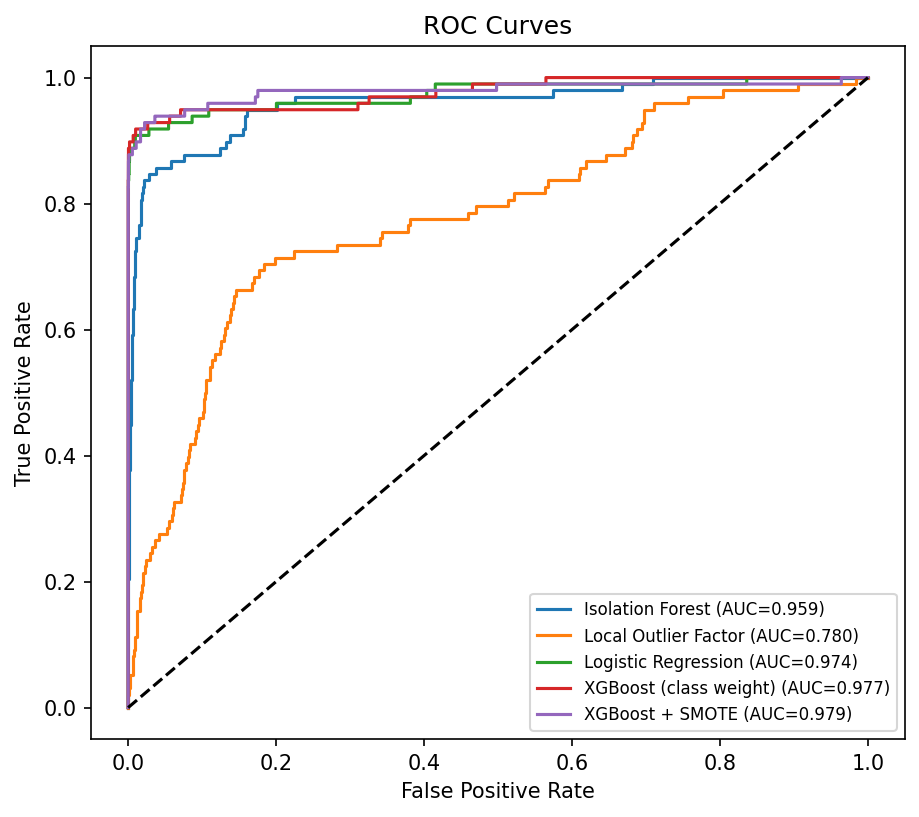

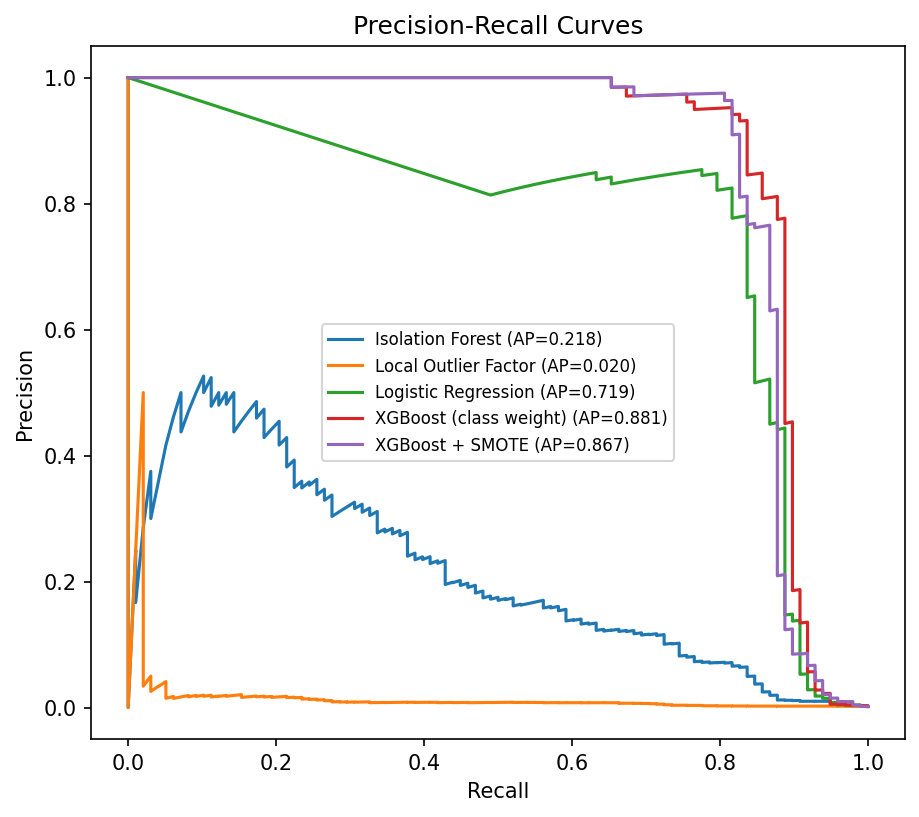

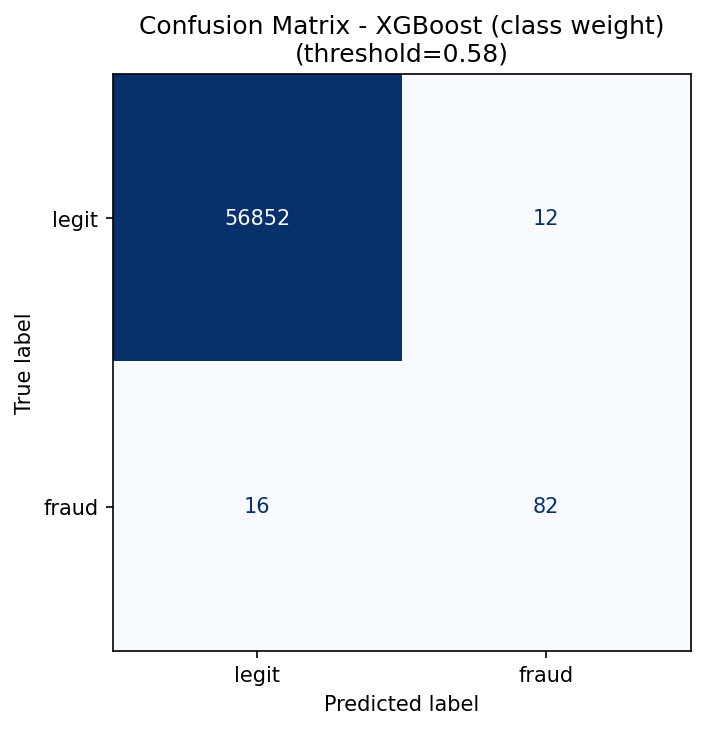

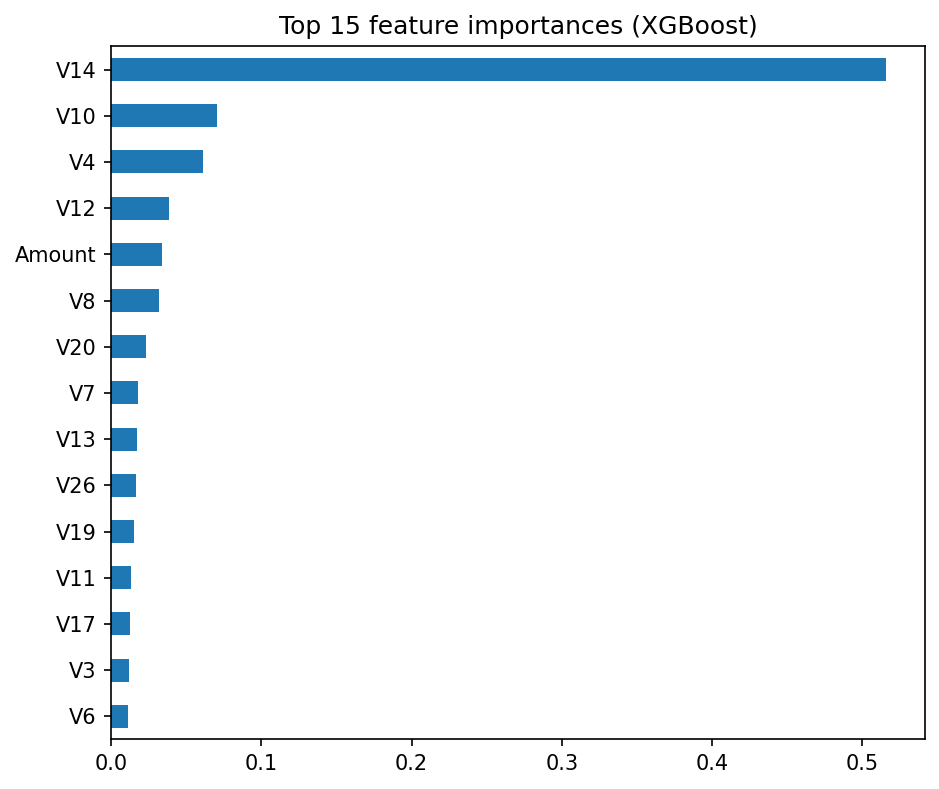

In [8]:
from IPython.display import Image, display
for f in ["roc_curve.png", "pr_curve.png", "confusion_matrix.png", "feature_importance.png"]:
    display(Image(f, width=520))

## 7. Save the model for the web app
The model, scaler, threshold and column order are saved together so `app.py` can reproduce the exact same preprocessing.

In [9]:
joblib.dump({"model": best_model, "scaler": scaler, "threshold": float(best_thr),
             "columns": list(X.columns), "name": best_name}, "fraud_model.joblib")

# raw (unscaled) rows from the test set so the app can show real examples
raw = pd.read_csv("creditcard.csv.gz")
test_raw = raw.loc[X_test.index]
samples = pd.concat([test_raw[test_raw.Class == 1].sample(10, random_state=1),
                     test_raw[test_raw.Class == 0].sample(10, random_state=1)])
samples.to_csv("sample_transactions.csv", index=False)

with open("results.txt", "w") as f:
    f.write("Fraud detection results (test set, %d transactions, %d frauds)\n\n" % (len(y_test), y_test.sum()))
    f.write(res_df.to_string())
    f.write(f"\n\nBest model: {best_name}, threshold = {best_thr:.3f}\n")
    f.write("Confusion matrix [[TN FP] [FN TP]]:\n" + str(cm) + "\n")
print("done")

done


## 8. Conclusion
- **XGBoost (class weights)** was the best model: PR-AUC 0.88, precision 0.87, recall 0.84. On the test set it caught 82 of 98 frauds with only 12 false alarms among 56,864 normal transactions.
- **Logistic Regression** catches most frauds but flags far too many normal transactions (precision 0.06). Its ROC-AUC still looks great (0.974), which is exactly why ROC-AUC is misleading on imbalanced data.
- **Isolation Forest / LOF** (no labels) did much worse than the supervised models.
- **SMOTE** gave higher precision but lower recall than class weights, with similar PR-AUC.

**Limitations:** random split instead of time-based, only 98 frauds in the test set (noisy metrics), anonymized features (no business interpretation).
**Next steps:** time-based validation, cost-sensitive threshold, hyperparameter tuning with cross-validation, SHAP explanations.